# Late deliveries: how often, what they cost, and where they come from

**Question.** Olist promises each customer a delivery date. When it misses, what happens to reviews and repeat
purchases, and where should the business look first to fix it?

**Data.** dbt marts built from the public Olist dataset (99,441 orders, Sep 2016 - Oct 2018). Metric definitions live
in `dbt/models/marts/metrics.md`. "Late" means delivered on a calendar day after the promised date.

Run `python ingest/load_raw.py` and `dbt build` first. This notebook only reads the `marts` schema.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)
IMG = ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)


def sql(q):
    return con.sql(q).df()


# Reference palette: slot 1 blue = on time / baseline, slot 2 orange = late.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def two_prop_test(x1, n1, x2, n2):
    """Two-sided z-test for p1 - p2, with a 95% CI on the difference."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1 - p2, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se), 2 * stats.norm.sf(abs(z))


def fmt_p(p):
    return "< 0.0001" if p < 1e-4 else f"= {p:.4f}"

## 1. Headline numbers

In [2]:
kpi = sql("""
    select
        count(*)                                        as orders,
        round(sum(order_value))                         as gmv_brl,
        round(sum(order_value) / count(*), 2)           as aov_brl,
        round(100 * avg(is_late::int) filter (where is_delivered), 1) as late_rate_pct,
        sum(is_late::int)                               as late_orders,
        round(sum(order_value) filter (where is_late))  as late_gmv_brl,
        round(avg(review_score), 2)                     as avg_review
    from marts.fct_orders
    where not is_canceled
""")
kpi.T

,0
orders,98207.00
gmv_brl,15735527.00
aov_brl,160.23
late_rate_pct,6.80
late_orders,6534.00
late_gmv_brl,1150892.00
avg_review,4.12


About 1 in 15 delivered orders arrives late. That is a small share of orders, so the question is whether those
orders hurt more than their share suggests.

## 2. When does lateness happen?

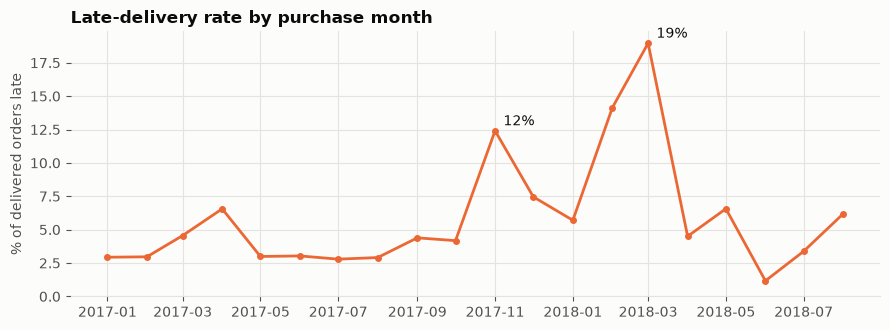

In [3]:
monthly = sql("""
    select date_trunc('month', purchase_date) as month, count(*) as orders,
           100 * avg(is_late::int) as late_pct
    from marts.fct_orders
    where is_delivered and purchase_date >= '2017-01-01'
    group by 1 order by 1
""")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.month, monthly.late_pct, color=ORANGE, lw=2, marker="o", ms=4)
for m in ["2017-11-01", "2018-03-01"]:
    row = monthly[monthly.month == m].iloc[0]
    ax.annotate(f"{row.late_pct:.0f}%", (row.month, row.late_pct), xytext=(6, 4), textcoords="offset points", color=INK)
ax.set_title("Late-delivery rate by purchase month")
ax.set_ylabel("% of delivered orders late")
ax.set_ylim(0, None)
fig.tight_layout()
fig.savefig(IMG / "late_rate_by_month.png", dpi=160)

Lateness is not steady. It runs at 3-5% most months and jumps in **November 2017 (12%, the Black Friday month)** and
**February-March 2018 (14% and 19%)**. These spikes are when a fixed promise date is most likely to break, which
points to promise dates that do not flex with load. The dataset does not say what caused the 2018 spike.

## 3. Does a late delivery hurt the review?

,bucket,sort_key,orders,bad_review_pct,avg_score
0,7+ days early,-147,75749,9.002099,4.312809
1,0-6 days early,-6,13699,10.759909,4.165487
2,1-3 days late,1,1852,32.127430,3.291037
3,4-7 days late,4,1748,67.677346,2.102975
4,8+ days late,8,2782,79.259526,1.696621


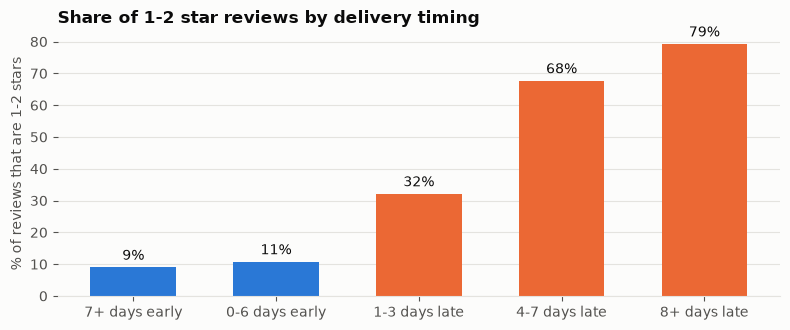

In [4]:
buckets = sql("""
    select
        case when delay_days <= -7 then '7+ days early'
             when delay_days <= 0  then '0-6 days early'
             when delay_days <= 3  then '1-3 days late'
             when delay_days <= 7  then '4-7 days late'
             else '8+ days late' end as bucket,
        min(delay_days) as sort_key,
        count(*) as orders,
        100 * avg((review_score <= 2)::int) as bad_review_pct,
        avg(review_score) as avg_score
    from marts.fct_orders
    where is_delivered and review_score is not null
    group by 1 order by sort_key
""")

fig, ax = plt.subplots(figsize=(8, 3.4))
colors = [BLUE, BLUE, ORANGE, ORANGE, ORANGE]
bars = ax.bar(buckets.bucket, buckets.bad_review_pct, color=colors, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color=INK)
ax.set_title("Share of 1-2 star reviews by delivery timing")
ax.set_ylabel("% of reviews that are 1-2 stars")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(IMG / "bad_reviews_by_delay.png", dpi=160)
buckets

In [5]:
scores = sql("select is_late, review_score from marts.fct_orders where is_delivered and review_score is not null")
late, ontime = scores[scores.is_late].review_score, scores[~scores.is_late].review_score
u = stats.mannwhitneyu(late, ontime, alternative="less")
diff, ci, p = two_prop_test((late <= 2).sum(), len(late), (ontime <= 2).sum(), len(ontime))
print(f"Mean score: late {late.mean():.2f} vs on time {ontime.mean():.2f} (median {late.median():.0f} vs {ontime.median():.0f})")
print(f"Mann-Whitney U (late < on time): p {fmt_p(u.pvalue)}")
print(f"1-2 star share: late {100*(late<=2).mean():.1f}% vs on time {100*(ontime<=2).mean():.1f}%, "
      f"difference {100*diff:.1f} pts (95% CI {100*ci[0]:.1f} to {100*ci[1]:.1f}), p {fmt_p(p)}")

Mean score: late 2.27 vs on time 4.29 (median 1 vs 5)
Mann-Whitney U (late < on time): p < 0.0001
1-2 star share: late 62.4% vs on time 9.3%, difference 53.1 pts (95% CI 51.9 to 54.3), p < 0.0001


The effect is large and has a sharp edge. Orders that arrive early or on the day get 1-2 star reviews about 9-11% of
the time. **One to three days late triples that to 32%**, and past four days late most reviews are 1-2 stars. The
median review drops from 5 stars to 1.

Could region explain this, since some regions get more late orders and might also review more harshly? The check
below compares late vs on-time orders within each region.

In [6]:
REGION = """case
    when customer_state in ('SP','RJ','MG','ES') then 'Southeast'
    when customer_state in ('PR','SC','RS') then 'South'
    when customer_state in ('DF','GO','MT','MS') then 'Center-West'
    when customer_state in ('AM','PA','AC','AP','RO','RR','TO') then 'North'
    else 'Northeast' end"""

sql(f"""
    select {REGION} as region,
        round(100 * avg((review_score <= 2)::int) filter (where not is_late), 1) as bad_pct_on_time,
        round(100 * avg((review_score <= 2)::int) filter (where is_late), 1)     as bad_pct_late,
        count(*) filter (where is_late) as late_orders
    from marts.fct_orders
    where is_delivered and review_score is not null
    group by 1 order by late_orders desc
""")

,region,bad_pct_on_time,bad_pct_late,late_orders
0,Southeast,9.2,61.9,3953
1,Northeast,9.9,64.9,1121
2,South,8.9,59.7,799
3,Center-West,9.6,64.3,361
4,North,10.5,66.2,148


The gap holds in every region at roughly the same size, so region is not driving it.

## 4. Does a late first order cost the repeat purchase?

Only first orders placed before March 2018 are counted, so every customer has at least six months in which they
could have come back. Repeat buying is rare on Olist overall (about 3% of customers), so the absolute numbers are small.

In [7]:
first = sql(f"""
    select f.is_late, {REGION} as region, d.is_repeat_customer
    from marts.fct_orders f
    join marts.dim_customer d using (customer_unique_id)
    where f.customer_order_number = 1 and f.is_delivered and f.purchase_date < '2018-03-01'
""")
g = first.groupby("is_late").is_repeat_customer.agg(["sum", "count"])
diff, ci, p = two_prop_test(g.loc[True, "sum"], g.loc[True, "count"], g.loc[False, "sum"], g.loc[False, "count"])
rate_late, rate_ok = g.loc[True, "sum"] / g.loc[True, "count"], g.loc[False, "sum"] / g.loc[False, "count"]
print(f"Repeat rate: late first order {100*rate_late:.2f}% vs on time {100*rate_ok:.2f}% "
      f"({100*(rate_late/rate_ok-1):.0f}% relative), difference {100*diff:.2f} pts "
      f"(95% CI {100*ci[0]:.2f} to {100*ci[1]:.2f}), p {fmt_p(p)}")

(first.groupby(["region", "is_late"]).is_repeat_customer.mean().mul(100).round(2)
      .unstack().rename(columns={False: "repeat_pct_on_time", True: "repeat_pct_late"}))

Repeat rate: late first order 3.05% vs on time 4.13% (-26% relative), difference -1.08 pts (95% CI -1.66 to -0.50), p = 0.0014


is_late,repeat_pct_on_time,repeat_pct_late
region,,
Center-West,4.01,3.12
North,3.87,2.86
Northeast,3.22,2.63
South,3.77,4.45
Southeast,4.36,2.85


Customers whose first order arrived late came back about a quarter less often. The difference is statistically
significant, but read it with two caveats:
- It is an association, not a controlled experiment. Late orders differ from on-time ones in other ways too.
- The gap shows up in four of five regions, including the two largest (Southeast and Northeast). The South
  reverses it. Repeat buyers are rare, so each region's rate rests on a small number of customers.

## 5. Where does lateness come from?

### Seller or carrier?
Each order item carries the seller's shipping deadline. If the seller handed the parcel to the carrier after that
deadline, the seller contributed to the delay. If not, the delay happened after handover.

In [8]:
cause = sql("""
    with o as (
        select order_id, bool_or(seller_shipped_late) as seller_late
        from marts.fct_order_items where is_late group by 1
    )
    select round(100 * avg(seller_late::int), 1) as pct_late_orders_seller_shipped_late, count(*) as late_orders from o
""")
cause

,pct_late_orders_seller_shipped_late,late_orders
0,27.8,6535


**Only about 28% of late orders had a seller ship late.** The other ~72% left the seller on time and were still late,
so the larger lever is the carrier leg and the promise date itself, not seller discipline.

### Geography

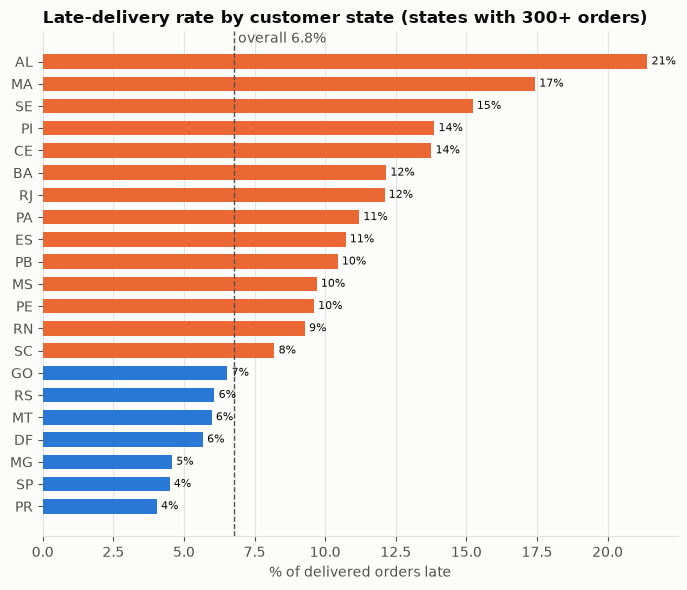

In [9]:
states = sql("""
    select customer_state as state, count(*) as orders, 100 * avg(is_late::int) as late_pct
    from marts.fct_orders where is_delivered
    group by 1 having count(*) >= 300 order by late_pct
""")
overall = sql("select 100 * avg(is_late::int) as p from marts.fct_orders where is_delivered").p[0]

fig, ax = plt.subplots(figsize=(7, 6))
colors = [ORANGE if v > overall else BLUE for v in states.late_pct]
bars = ax.barh(states.state, states.late_pct, color=colors, height=0.65)
ax.axvline(overall, color=INK_2, lw=1, ls="--")
ax.text(overall, len(states) - 0.3, f" overall {overall:.1f}%", color=INK_2, va="bottom")
ax.bar_label(bars, fmt="%.0f%%", padding=3, color=INK, fontsize=8)
ax.set_title("Late-delivery rate by customer state (states with 300+ orders)")
ax.set_xlabel("% of delivered orders late")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMG / "late_rate_by_state.png", dpi=160)

Geography matters much more than product category (see below). São Paulo, where most sellers are based, runs at
about 4.5%. Rio de Janeiro is around 12% and many Northeast states are at 12-21%. Rio alone has over 12,000
delivered orders, so it is the biggest single pool of late orders after São Paulo.

In [10]:
sql("""
    select p.category, count(distinct i.order_id) as orders, round(100 * avg(i.is_late::int), 1) as late_pct
    from marts.fct_order_items i join marts.dim_product p using (product_id)
    where i.is_late is not null
    group by 1 having count(distinct i.order_id) >= 1000
    order by late_pct desc
""").set_index("category").T

category,office_furniture,baby,health_beauty,electronics,unknown,watches_gifts,auto,bed_bath_table,furniture_decor,telephony,...,computers_accessories,perfumery,toys,sports_leisure,consoles_games,cool_stuff,fashion_bags_accessories,housewares,pet_shop,luggage_accessories
orders,1254.0,2809.0,8649.0,2517.0,1392.0,5493.0,3809.0,9272.0,6307.0,4093.0,...,6529.0,3088.0,3804.0,7530.0,1018.0,3559.0,1821.0,5743.0,1688.0,1019.0
late_pct,8.0,7.7,7.6,7.6,7.5,7.2,7.0,7.0,7.0,7.0,...,6.5,6.5,6.4,6.3,5.9,5.8,5.3,5.0,4.9,4.2


Across the 22 categories with 1,000+ orders, late rates only range from about 4% to 8%. Category is a weak signal.

### Sellers
The top 10% of sellers by late orders account for most late orders, but they also handle most orders. The fair
question is which sellers are late **more often than their volume predicts**. The test below flags sellers with at
least 50 delivered orders whose late rate is significantly above the platform rate (one-sided binomial test,
Bonferroni-corrected for the number of sellers tested).

In [11]:
sellers = sql("""
    select seller_id, count(distinct order_id) as orders,
           count(distinct order_id) filter (where is_late) as late_orders
    from marts.fct_order_items where is_late is not null
    group by 1 having count(distinct order_id) >= 50
""")
base = overall / 100
sellers["late_pct"] = 100 * sellers.late_orders / sellers.orders
sellers["p"] = [stats.binomtest(k, n, base, alternative="greater").pvalue for k, n in zip(sellers.late_orders, sellers.orders)]
flagged = sellers[sellers.p < 0.05 / len(sellers)].sort_values("late_orders", ascending=False)
excess = (flagged.late_orders - flagged.orders * base).sum()
total_late = sql("select sum(is_late::int) as n from marts.fct_orders").n[0]
print(f"{len(flagged)} of {len(sellers)} sellers with 50+ orders are late significantly more than the platform rate.")
print(f"They account for {flagged.late_orders.sum():,} late orders, about {excess:,.0f} more than their volume predicts "
      f"({100*excess/total_late:.0f}% of all late orders).")
flagged.head(10).round(3)

11 of 425 sellers with 50+ orders are late significantly more than the platform rate.
They account for 630 late orders, about 292 more than their volume predicts (4% of all late orders).


,seller_id,orders,late_orders,late_pct,p
318,4a3ca9315b744ce9f8e9374361493884,1772,172,9.707,0.0
234,4869f7a5dfa277a7dca6462dcf3b52b2,1124,118,10.498,0.0
323,06a2c3af7b3aee5d69171b0e14f0ee87,389,74,19.023,0.0
395,7d13fca15225358621be4086e1eb0964,558,64,11.470,0.0
4,8160255418d5aaa7dbdc9f4c64ebda44,380,52,13.684,0.0
238,88460e8ebdecbfecb5f9601833981930,246,42,17.073,0.0
173,e5a3438891c0bfdb9394643f95273d8e,216,34,15.741,0.0
361,54965bbe3e4f07ae045b90b0b8541f52,73,22,30.137,0.0
285,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,21.875,0.0
326,712e6ed8aa4aa1fa65dab41fed5737e4,77,16,20.779,0.0


## Findings

1. **Late delivery is the strongest driver of bad reviews in the data.** Arriving even 1-3 days late triples the
   share of 1-2 star reviews (about 10% to 32%), and past 4 days late most reviews are 1-2 stars. This holds within
   every region.
2. **It is linked to lost repeat business.** Customers whose first order was late returned about a quarter less often.
   The base repeat rate is low, so this is a modest absolute effect, and it is an association rather than proof.
3. **Most lateness happens after the seller ships.** About 72% of late orders left the seller on time. The promise
   date and the carrier leg are the bigger levers.
4. **Geography and peak months drive risk; category does not.** Rio and the Northeast run 2-5x São Paulo's late rate,
   and late rates spike in peak months. Category spreads only 4-8%.
5. **Problem sellers exist but are not the main story.** Only 11 of 425 sellers with 50+ orders are late
   significantly more than their volume predicts, and they add about 4% of all late orders. Worth a seller-ops
   conversation, but the carrier leg and promise dates matter far more.

**What this sets up for the ML phase.** A late-delivery model should lean on route (seller state to customer state),
promised days, purchase month and seller history, using only what is known at purchase time. The cost framing
comes from finding 1: each late order turns a ~10% bad-review risk into a 32-80% one.